# **Tensorflow Regression Project**

### **Introduction**

The **EV Energy Consumption Dataset** contains operational and environmental data related to electric vehicles (EVs), including features such as battery capacity, battery health, state of charge (SOC), vehicle speed, acceleration, road gradient, ambient temperature, tire pressure, HVAC usage, traffic conditions, passenger count, driving mode, and other vehicle-related parameters. The dataset is designed to analyze the factors influencing electric vehicle energy consumption and is widely used for energy analysis, predictive modeling, and machine learning applications in the electric mobility domain.

In this project, **Exploratory Data Analysis (EDA)** is performed using Python libraries such as **Pandas, NumPy, Matplotlib, and Seaborn** to understand the dataset's structure, identify patterns, detect outliers, examine feature distributions, and analyze the relationships between different variables. Various visualizations are used to study the impact of driving conditions, environmental factors, and vehicle characteristics on energy consumption.

Furthermore, **TensorFlow-based Deep Learning Regression** is applied to predict the energy consumption of electric vehicles based on the available input features. Data preprocessing techniques, including duplicate removal, feature engineering, categorical encoding, and feature scaling, are carried out to improve model performance. The trained regression model learns the relationship between the input variables and the target variable, **Energy_Consumption_kWh**, enabling accurate prediction of energy usage under different driving scenarios.

The main objective of this project is to gain meaningful insights into the factors affecting electric vehicle energy consumption and to develop a reliable regression model capable of accurately predicting energy usage. The project demonstrates the complete machine learning workflow, including data preprocessing, exploratory data analysis, feature engineering, TensorFlow model development, performance evaluation using **MAE, MSE, RMSE, and R² Score**, and visualization of prediction results.


### **Import Necessary Libraries**

In [66]:
#remove warning messages
import warnings
warnings.filterwarnings('ignore')

#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [67]:
''' Numpy  1.23.5
    Pandas  1.5.3
    Tensorflow 2.15.1
    Keras 2.15.0
'''

' Numpy  1.23.5\n    Pandas  1.5.3\n    Tensorflow 2.15.1\n    Keras 2.15.0\n'

### **Import Dataset**

In [68]:
df = pd.read_csv("EV_Energy_Consumption_Dataset_1.csv")

### **Display the first 5 rows**

In [69]:
df.head(5)

,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,1/1/2024 0:00,111.507366,-2.773816,30.415148,378.091525,25.314786,Sport,Highway,Low,6.879446,Fog,0.741770,42.172533,7.829253,31.112020,1822.967368,20.757508,12.054317
1,1435,1/1/2024 0:01,48.612323,-0.796982,97.385534,392.718377,18.240755,Eco,Urban,Low,-3.007212,Fog,-3.495516,57.018427,4.495572,31.504366,2091.831914,0.642918,4.488701
2,1860,1/1/2024 0:02,108.733320,0.253800,84.912600,398.993495,44.449145,Eco,Highway,High,0.029585,Clear,9.248275,69.028911,5.144489,33.838015,1816.702497,40.842824,11.701377
3,1270,1/1/2024 0:03,38.579484,-2.111395,28.777904,358.128273,28.980155,Eco,Urban,Medium,8.271943,Snow,2.868409,86.638349,4.518283,33.256014,1283.102642,5.305229,7.389266
4,1106,1/1/2024 0:04,57.172438,1.477883,29.740160,310.888162,33.184551,Sport,Highway,Low,2.776814,Rain,16.750244,27.189185,4.263406,33.579678,2160.350788,5.825926,6.761205


### **Dispaly the last 5 rows**

In [70]:
df.tail(5)

,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
4995,1289,1/4/2024 11:15,60.036619,-0.685606,78.360306,355.284001,23.338767,Sport,Highway,Medium,0.273436,Clear,2.678321,73.356245,13.936821,28.327849,1796.093041,47.102202,10.089577
4996,1294,1/4/2024 11:16,107.291944,1.674625,68.163963,375.453798,19.056652,Sport,Urban,Medium,9.793821,Snow,37.105374,78.446046,12.197087,29.155964,2095.099662,7.538642,9.600692
4997,1450,1/4/2024 11:17,110.384512,1.348736,72.918142,303.834905,28.155775,Eco,Rural,Medium,-0.429536,Clear,-2.955831,78.251840,1.595182,34.369795,2328.330539,5.644158,9.148392
4998,1903,1/4/2024 11:18,6.618791,-2.642843,91.904887,302.708366,31.781034,Sport,Highway,Medium,-3.366394,Snow,16.154754,74.929797,13.503355,33.363985,1274.506744,32.768008,5.581431
4999,1214,1/4/2024 11:19,98.476987,0.489050,82.716863,308.334933,24.703606,Eco,Highway,Low,-2.129397,Fog,29.660221,41.293694,0.359335,31.152982,1837.999134,12.633833,7.841474


### **Data Cleaning**

In [71]:
#Convert column name to standard type

df.columns = (df.columns
              .str.strip()
              .str.title()
              .str.replace(" ","_")
              .str.replace("-","_")
              .str.replace("%","")
              .str.rstrip('_')
              )

In [72]:
#Convert date columns to date format

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

In [73]:
#Check whether there is missing values

print(df.isnull().sum())

Vehicle_Id                0
Timestamp                 0
Speed_Kmh                 0
Acceleration_Ms2          0
Battery_State             0
Battery_Voltage_V         0
Battery_Temperature_C     0
Driving_Mode              0
Road_Type                 0
Traffic_Condition         0
Slope                     0
Weather_Condition         0
Temperature_C             0
Humidity                  0
Wind_Speed_Ms             0
Tire_Pressure_Psi         0
Vehicle_Weight_Kg         0
Distance_Travelled_Km     0
Energy_Consumption_Kwh    0
dtype: int64


In [74]:
#Check for duplicate values
df.duplicated().sum()

0

### **Data Understanding**

In [75]:
#Basic Information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Vehicle_Id              5000 non-null   int64         
 1   Timestamp               5000 non-null   datetime64[ns]
 2   Speed_Kmh               5000 non-null   float64       
 3   Acceleration_Ms2        5000 non-null   float64       
 4   Battery_State           5000 non-null   float64       
 5   Battery_Voltage_V       5000 non-null   float64       
 6   Battery_Temperature_C   5000 non-null   float64       
 7   Driving_Mode            5000 non-null   object        
 8   Road_Type               5000 non-null   object        
 9   Traffic_Condition       5000 non-null   object        
 10  Slope                   5000 non-null   float64       
 11  Weather_Condition       5000 non-null   object        
 12  Temperature_C           5000 non-null   float64 

In [76]:
# Use summary statistics to understand distribution
df.describe()

,Vehicle_Id,Speed_Kmh,Acceleration_Ms2,Battery_State,Battery_Voltage_V,Battery_Temperature_C,Slope,Temperature_C,Humidity,Wind_Speed_Ms,Tire_Pressure_Psi,Vehicle_Weight_Kg,Distance_Travelled_Km,Energy_Consumption_Kwh
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,1505.701200,59.312952,-0.019885,60.214465,351.118306,27.510130,2.504690,17.312654,55.302173,7.505087,31.503390,1854.719760,24.994042,8.437983
std,290.836902,34.517605,1.724287,23.128262,28.968372,10.015385,4.360854,13.005106,20.161289,4.325455,2.017357,373.685150,14.246454,2.184809
min,1000.000000,0.001396,-2.999683,20.020196,300.004812,10.003858,-4.991079,-4.995288,20.027119,0.000126,28.001891,1200.960317,0.107544,1.881426
25%,1253.000000,29.515400,-1.490240,40.088318,326.613439,18.884742,-1.235653,5.950476,37.970900,3.837738,29.772709,1531.417633,12.736568,6.771081
50%,1510.000000,58.646794,-0.043329,60.490283,351.510915,27.581710,2.452368,17.330798,55.650512,7.495373,31.484048,1865.006523,24.640458,8.455746
75%,1761.000000,89.030001,1.473887,80.409928,375.968140,35.920162,6.366990,28.624021,72.650838,11.291284,33.256528,2181.071491,37.562482,10.031938
max,1999.000000,119.946924,2.998039,99.993986,399.990098,44.985943,9.998358,39.998063,89.988891,14.999095,34.997829,2499.504564,49.993767,14.660528


## **Data Analysis and Visualization**

1. What Does the dataset contain ?

In [77]:
print("Number of Rows: ", df.shape[0])
print("Number of Columns: ", df.shape[1])

print("\nNumber of Unique Vehicles:")
print(df["Vehicle_Id"].nunique())

Number of Rows:  5000
Number of Columns:  19

Number of Unique Vehicles:
989


2. How much energy do the vehicles consume or distribution of Energy consumption ?

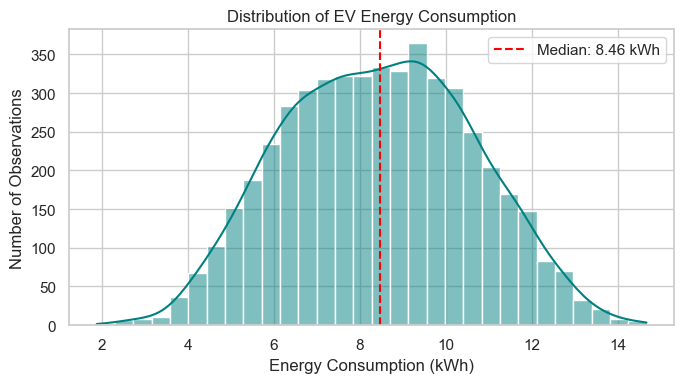

In [78]:
plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="Energy_Consumption_Kwh",
    bins=30,
    kde=True,
    color="teal"
)

median_value = df["Energy_Consumption_Kwh"].median()

plt.axvline(
    median_value,
    color="red",
    linestyle="--",
    label=f"Median: {median_value:.2f} kWh"
)

plt.title("Distribution of EV Energy Consumption")
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Number of Observations")
plt.legend()
plt.tight_layout()
plt.show()

This graph shows how energy consumtion varies accross all 5000 observations and where most of the observations are concentrated.

3. How Driving Speed affect Energy Consumption?

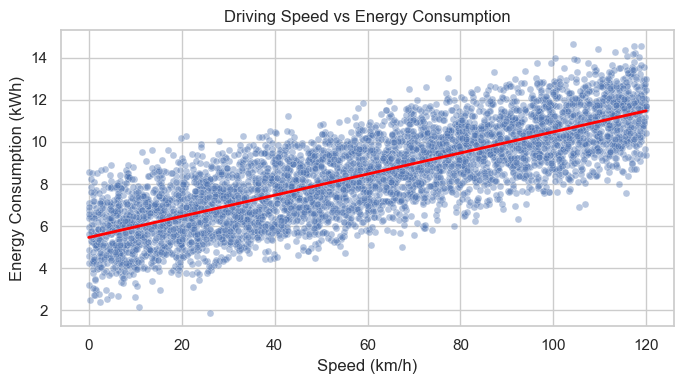

In [79]:
plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x="Speed_Kmh",
    y="Energy_Consumption_Kwh",
    alpha=0.4,
    s=25
)

# Add a trend line to show the overall relationship
sns.regplot(
    data=df,
    x="Speed_Kmh",
    y="Energy_Consumption_Kwh",
    scatter=False,
    color="red",
    line_kws={"linewidth": 2}
)

plt.title("Driving Speed vs Energy Consumption")
plt.xlabel("Speed (km/h)")
plt.ylabel("Energy Consumption (kWh)")
plt.tight_layout()
plt.show()

4. How distance travelled affect energy consumption?

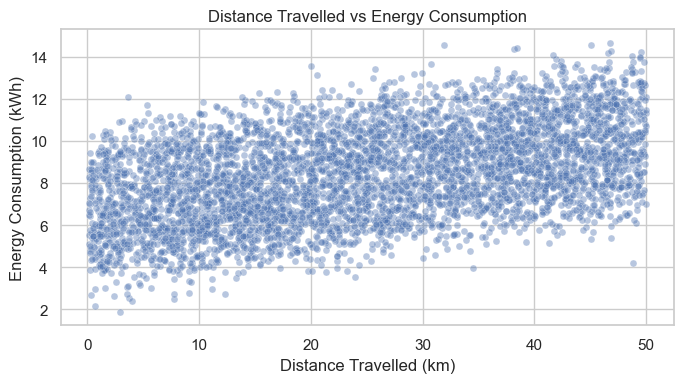

In [80]:
plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x="Distance_Travelled_Km",
    y="Energy_Consumption_Kwh",
    alpha=0.4,
    s=25
)

plt.title("Distance Travelled vs Energy Consumption")
plt.xlabel("Distance Travelled (km)")
plt.ylabel("Energy Consumption (kWh)")
plt.tight_layout()
plt.show()

5. Compare traffic, driving mode, road type and weather condition affect energy consumption?

In [81]:
def plot_average_consumption(column, title):
    summary = (
        df.groupby(column, observed=True)["Energy_Consumption_Kwh"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
        .reset_index()
    )

    plt.figure(figsize=(7, 4))

    ax = sns.barplot(
        data=summary,
        x=column,
        y="mean",
        color="teal",
        width=0.5
    )

    # Display the mean above each bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=1)

    plt.ylim(0, summary["mean"].max() * 1.15)

    plt.title(title)
    plt.xlabel(column.replace("_", " "))
    plt.ylabel("Average Energy Consumption (kWh)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Display the number of observations in each category
    display(summary.rename(columns={
        column: "Category",
        "mean": "Average Energy Consumption (kWh)",
        "count": "Number of Observations"
    }).round(2))

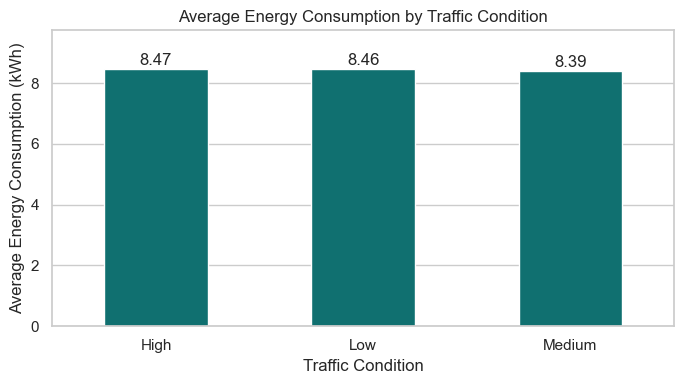

,Category,Average Energy Consumption (kWh),Number of Observations
0,High,8.47,1676
1,Low,8.46,1622
2,Medium,8.39,1702


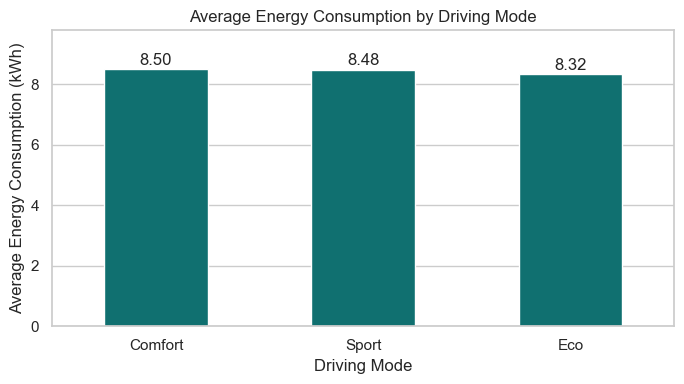

,Category,Average Energy Consumption (kWh),Number of Observations
0,Comfort,8.50,1668
1,Sport,8.48,1719
2,Eco,8.32,1613


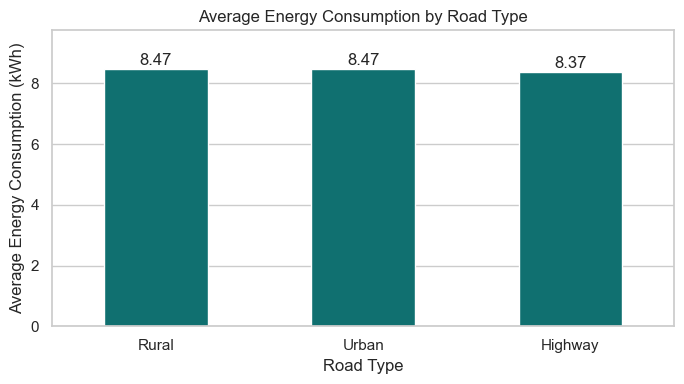

,Category,Average Energy Consumption (kWh),Number of Observations
0,Rural,8.47,1632
1,Urban,8.47,1732
2,Highway,8.37,1636


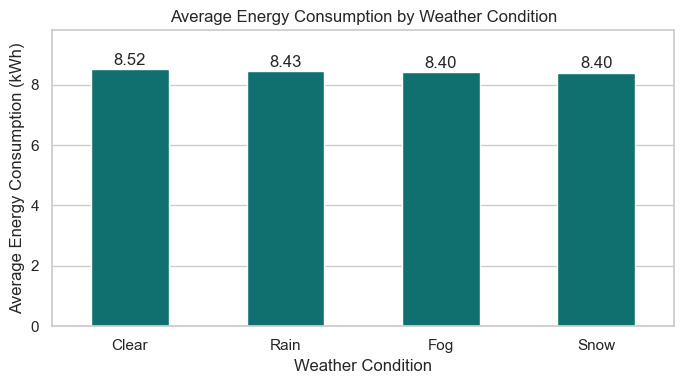

,Category,Average Energy Consumption (kWh),Number of Observations
0,Clear,8.52,1260
1,Rain,8.43,1279
2,Fog,8.40,1216
3,Snow,8.40,1245


In [82]:
plot_average_consumption(
    "Traffic_Condition",
    "Average Energy Consumption by Traffic Condition"
)

plot_average_consumption(
    "Driving_Mode",
    "Average Energy Consumption by Driving Mode"
)

plot_average_consumption(
    "Road_Type",
    "Average Energy Consumption by Road Type"
)

plot_average_consumption(
    "Weather_Condition",
    "Average Energy Consumption by Weather Condition"
)

6. How Temperature affects Energy consumption?

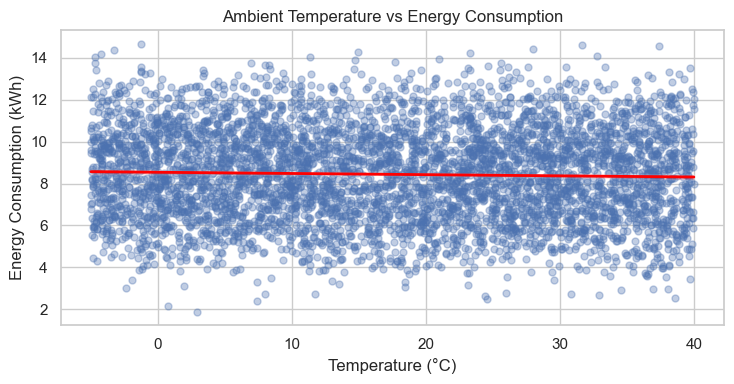

In [83]:
plt.figure(figsize=(7.5, 4))

sns.regplot(
    data=df,
    x="Temperature_C",
    y="Energy_Consumption_Kwh",
    scatter_kws={"alpha": 0.35, "s": 25},
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("Ambient Temperature vs Energy Consumption")
plt.xlabel("Temperature (°C)")
plt.ylabel("Energy Consumption (kWh)")
plt.tight_layout()
plt.show()

7. Average energy consumption throughout the day ?

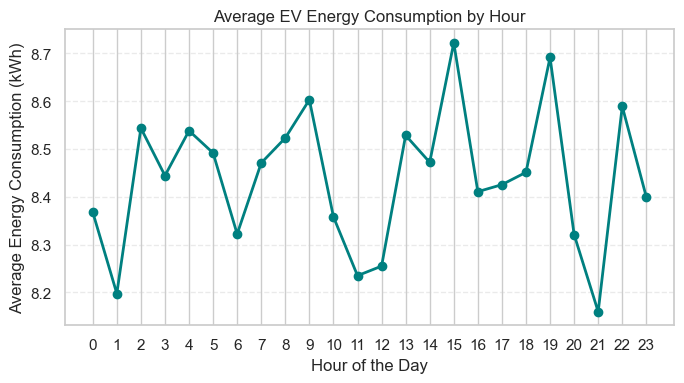

In [84]:
df["Hour"] = df["Timestamp"].dt.hour

hourly_energy = (
    df.groupby("Hour")["Energy_Consumption_Kwh"]
    .mean()
    .reindex(range(24))
)

plt.figure(figsize=(7, 4))

plt.plot(
    hourly_energy.index,
    hourly_energy.values,
    marker="o",
    linewidth=2,
    color="teal"
)

plt.title("Average EV Energy Consumption by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Energy Consumption (kWh)")
plt.xticks(range(24))
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

8. Which numerical factors are related to energy consumption?

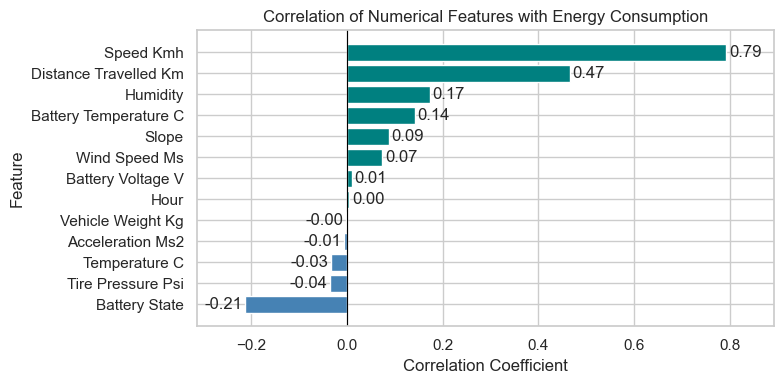

In [85]:
correlation = (
    df.select_dtypes(include="number")
    .corr()["Energy_Consumption_Kwh"]
    .drop(labels=["Energy_Consumption_Kwh"], errors="ignore")
    .drop(labels=["Vehicle_Id"], errors="ignore")
    .sort_values()
)

plt.figure(figsize=(8, 4))

colors = [
    "steelblue" if value < 0 else "teal"
    for value in correlation.values
]

bars = plt.barh(
    correlation.index.str.replace("_", " "),
    correlation.values,
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.bar_label(bars, fmt="%.2f", padding=2)

plt.xlim(correlation.min() - 0.1, correlation.max() + 0.1)

plt.title("Correlation of Numerical Features with Energy Consumption")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## **EDA Conclusion**

Exploratory Data Analysis (EDA) was performed to understand the distribution of EV energy consumption and explore its relationships with different driving and environmental conditions.

The analysis examined energy consumption in relation to driving speed, distance travelled, traffic conditions, driving mode, road type, weather conditions, ambient temperature, and time of day. Numerical feature correlations were also explored to identify potential relationships with energy consumption.

The visualisations helped identify patterns and differences across these variables and provided a better understanding of the dataset before model development. However, these relationships represent associations in the data and do not necessarily imply causation.

The insights gained from EDA will help guide feature selection and preprocessing for the TensorFlow regression model developed to predict EV energy consumption.

## **Regression**

In [86]:
#import Libraries

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [87]:
# Ordinal encoding: preserve the natural order
traffic_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

df["Traffic_Condition"] = (
    df["Traffic_Condition"].map(traffic_mapping)
)

# One-hot encode nominal columns
nominal_cols = [
    "Driving_Mode",
    "Road_Type",
    "Weather_Condition"
]

df = pd.get_dummies(
    df,
    columns=nominal_cols,
    dtype=int
)

print(df.head())
print("Final columns:", df.columns.tolist())

   Vehicle_Id           Timestamp   Speed_Kmh  Acceleration_Ms2  \
0        1102 2024-01-01 00:00:00  111.507366         -2.773816   
1        1435 2024-01-01 00:01:00   48.612323         -0.796982   
2        1860 2024-01-01 00:02:00  108.733320          0.253800   
3        1270 2024-01-01 00:03:00   38.579484         -2.111395   
4        1106 2024-01-01 00:04:00   57.172438          1.477883   

   Battery_State  Battery_Voltage_V  Battery_Temperature_C  Traffic_Condition  \
0      30.415148         378.091525              25.314786                  0   
1      97.385534         392.718377              18.240755                  0   
2      84.912600         398.993495              44.449145                  2   
3      28.777904         358.128273              28.980155                  1   
4      29.740160         310.888162              33.184551                  0   

      Slope  Temperature_C  ...  Driving_Mode_Comfort  Driving_Mode_Eco  \
0  6.879446       0.741770  ...    

In [88]:
X = df.drop(columns=['Energy_Consumption_Kwh','Vehicle_Id', 'Timestamp'])
y = df['Energy_Consumption_Kwh']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (5000, 24)
Target: (5000,)


In [89]:
# The rows are still in timestamp order
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Scale the input features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (4000, 24)
Testing data: (1000, 24)


In [111]:
tf.random.set_seed(42)

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(1024, activation="relu"),

    # One continuous numerical prediction
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
100/100 [==============================] - 2s 10ms/step - loss: 16.6229 - mae: 2.8530 - val_loss: 0.4608 - val_mae: 0.5409
Epoch 2/100
100/100 [==============================] - 1s 6ms/step - loss: 0.4597 - mae: 0.5427 - val_loss: 0.4321 - val_mae: 0.5301
Epoch 3/100
100/100 [==============================] - 1s 7ms/step - loss: 0.4042 - mae: 0.5066 - val_loss: 0.3981 - val_mae: 0.5078
Epoch 4/100
100/100 [==============================] - 1s 11ms/step - loss: 0.3688 - mae: 0.4836 - val_loss: 0.4009 - val_mae: 0.5119
Epoch 5/100
100/100 [==============================] - 1s 11ms/step - loss: 0.3415 - mae: 0.4639 - val_loss: 0.3529 - val_mae: 0.4792
Epoch 6/100
100/100 [==============================] - 1s 9ms/step - loss: 0.3165 - mae: 0.4490 - val_loss: 0.3622 - val_mae: 0.4839
Epoch 7/100
100/100 [==============================] - 1s 8ms/step - loss: 0.2958 - mae: 0.4322 - val_loss: 0.3629 - val_mae: 0.4899
Epoch 8/100
100/100 [==============================] - 1s 5ms/ste

In [115]:
y_pred = model.predict(X_test_scaled).ravel()

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error:  {mae:.4f} kWh")
print(f"Root Mean Squared Error: {rmse:.4f} kWh")
print(f"R²:   {r2*100:.2f}%")

32/32 [==============================] - 0s 3ms/step
Mean Absolute Error:  0.4371 kWh
Root Mean Squared Error: 0.5485 kWh
R²:   93.90%


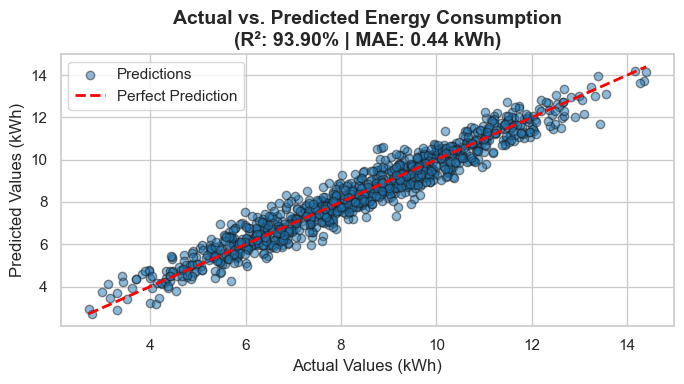

In [116]:
# Set a clean visual style
sns.set_theme(style="whitegrid",)
plt.figure(figsize=(7, 4))

# Create the scatter plot
plt.scatter(y_test, y_pred, alpha=0.5, color='#1f77b4', edgecolors='k', label='Predictions')

# Add a perfect diagonal baseline (Ideal Model Line)
perfect_line_range = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(perfect_line_range, perfect_line_range, color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

# Titles and labels (using your kWh unit)
plt.title(f'Actual vs. Predicted Energy Consumption\n(R²: {r2*100:.2f}% | MAE: {mae:.2f} kWh)', fontsize=14, fontweight='bold')
plt.xlabel('Actual Values (kWh)', fontsize=12)
plt.ylabel('Predicted Values (kWh)', fontsize=12)
plt.legend(loc='upper left')
plt.tight_layout()

# Show the plot
plt.show()


## **Conclusion**

The TensorFlow-based regression model achieved an **R² score of 93.90%**, indicating that it explains a substantial proportion of the variation in EV energy consumption on the test dataset. It recorded a **Mean Absolute Error (MAE) of 0.4371 kWh** and a **Root Mean Squared Error (RMSE) of 0.5485 kWh**, demonstrating promising predictive performance.

Overall, the model shows potential for estimating EV energy consumption using vehicle, driving, road, traffic, weather, and time-related features. Further testing on unseen data from different vehicles and time periods is recommended to evaluate its generalization ability and real-world reliability.